# Bài tập Thực hành 5: Mini-Project – Phân loại Âm thanh (Audio Classification) với 2D-CNN / ResNet bằng PyTorch Audio Pipeline

Trong bài tập thực hành nâng cao này, các bạn sẽ ứng dụng các biểu diễn không gian - thời gian 2D (Spectrogram) vào một quy trình Deep Learning phân loại âm thanh hoàn chỉnh (**Audio Torch Pipeline**) sử dụng PyTorch:

1. **Tải & Nạp Dữ liệu Âm thanh**: Sử dụng bộ dữ liệu `Speech Commands Dataset` từ internet, xây dựng lớp PyTorch `Dataset` và `DataLoader` để đọc và chuẩn hóa dạng sóng Waveform.
2. **Chuyển đổi Biểu diễn On-the-Fly**: Thiết lập các phép biến đổi trực tiếp trên PyTorch/Torchaudio:
   - Dạng sóng thô **Raw 1D Waveform**.
   - Phổ tần số tuyến tính **Linear Spectrogram (STFT)** quy đổi sang dB.
   - Phổ tần số thang đo cảm nhận **Log-Mel Spectrogram (80 Mel bands)** quy đổi sang dB.
3. **Xây dựng Mạng Neural PyTorch**: Thiết kế mạng CNN 1D cho Waveform và mạng CNN 2D cho Spectrogram.
4. **Huấn luyện & Đánh giá Mô hình**: Lập trình vòng lặp huấn luyện (Training Loop) với tối ưu hóa Adam và CrossEntropyLoss.
5. **Thực nghiệm So sánh**: So sánh hiệu năng phân loại giữa **Raw 1D-CNN** vs **Linear Spectrogram 2D-CNN** vs **Log-Mel Spectrogram 2D-CNN**.
6. **Trực quan hóa & Thảo luận**: Vẽ biểu đồ học tập (Learning Curves), ma trận nhầm lẫn (Confusion Matrix) và phân tích vai trò của thang đo Mel/Logarit.

## 1. Import các thư viện cần thiết
Chạy cell dưới đây để nạp các thư viện PyTorch (`torch`, `torch.nn`, `torchaudio`), nạp file (`urllib`, `zipfile`, `glob`), xử lý âm thanh (`librosa`), xử lý mảng số (`numpy`), đánh giá (`sklearn.metrics`) và trực quan hóa (`matplotlib`, `seaborn`).

In [1]:
# Chạy lệnh này trong terminal nếu chưa cài đặt thư viện:
# pip install torch torchaudio librosa numpy matplotlib scikit-learn seaborn scipy

import os
import glob
import zipfile
import urllib.request
import time
import copy
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchaudio
import torchaudio.transforms as T
from sklearn.metrics import classification_report, confusion_matrix

# Thiết lập thiết bị tính toán (CPU hoặc GPU/CUDA)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"PyTorch version: {torch.__version__}")
print(f"Torchaudio version: {torchaudio.__version__}")
print(f"Dang su dung thiet bi: {device}")


PyTorch version: 2.9.1+cu128
Torchaudio version: 2.9.1+cu128
Dang su dung thiet bi: cuda


## 2. Tải Dữ liệu Âm thanh & Lập trình Lớp PyTorch `AudioDataset`
Chúng ta tải bộ dữ liệu **Mini Speech Commands Dataset** và chọn 4 lớp lệnh giọng nói cơ bản: `['yes', 'no', 'up', 'down']`.
Lớp `AudioDataset` kế thừa từ `torch.utils.data.Dataset` sẽ:
1. Đọc file âm thanh `.wav` bằng `torchaudio.load()` hoặc `librosa.load()`.
2. Chuẩn hóa độ dài tín hiệu dạng sóng về cố định $1\text{ giây}$ ($16000\text{ samples}$ ở tần số lấy mẫu $16000\text{ Hz}$) bằng cách đệm số 0 (padding) hoặc cắt ngắn (cropping).
3. Trả về tensor dạng sóng $1D$ kích thước `(1, 16000)` cùng nhãn nhị phân/đa lớp `y`.

In [2]:
# TODO 1: Viết lớp SpeechCommandsDataset kế thừa torch.utils.data.Dataset
url = 'https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip'
zip_path = 'mini_speech_commands.zip'
extract_dir = 'dataset_speech_commands'

shared_extract_dir = os.path.join('..', 'day 54 25-8-2026', 'dataset_speech_commands')
if not os.path.exists(extract_dir) and os.path.exists(shared_extract_dir):
    extract_dir = shared_extract_dir

if not os.path.exists(zip_path) and not os.path.exists(extract_dir):
    print("Dang tai bo du lieu Speech Commands tu internet...")
    urllib.request.urlretrieve(url, zip_path)

if not os.path.exists(extract_dir):
    print("Dang giai nen bo du lieu...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

CLASSES = ['yes', 'no', 'up', 'down']
label_to_idx = {cls: idx for idx, cls in enumerate(CLASSES)}

class SpeechCommandsDataset(Dataset):
    def __init__(self, root_dir, classes, max_samples_per_class=250, target_sr=16000):
        self.file_list = []
        self.labels = []
        self.target_sr = target_sr
        self.target_length = target_sr

        dataset_dir = os.path.join(root_dir, 'mini_speech_commands')
        for class_name in classes:
            wav_files = sorted(glob.glob(os.path.join(dataset_dir, class_name, '*.wav')))
            self.file_list.extend(wav_files[:max_samples_per_class])
            self.labels.extend([label_to_idx[class_name]] * min(len(wav_files), max_samples_per_class))

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        audio, sample_rate = librosa.load(
            self.file_list[idx], sr=self.target_sr, mono=True
        )
        waveform = torch.tensor(audio, dtype=torch.float32).unsqueeze(0)

        if waveform.shape[1] < self.target_length:
            waveform = torch.nn.functional.pad(
                waveform, (0, self.target_length - waveform.shape[1])
            )
        else:
            waveform = waveform[:, :self.target_length]

        label = self.labels[idx]
        return waveform, label

full_dataset = SpeechCommandsDataset(extract_dir, CLASSES, max_samples_per_class=250)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Tong so mau du lieu: {len(full_dataset)} (Train: {len(train_dataset)}, Val: {len(val_dataset)})")

Tong so mau du lieu: 1000 (Train: 800, Val: 200)


## 3. Xây dựng các Phép Biến đổi Âm thanh (Audio Transforms) On-the-Fly
Chúng ta thiết lập 3 đường ống chuyển đổi dữ liệu (Transforms) bằng `torchaudio.transforms`:
1. **Raw 1D Waveform**: Giữ nguyên tín hiệu dạng sóng $1D$ `(1, 16000)`.
2. **Linear Spectrogram (STFT)**: Sử dụng `torchaudio.transforms.Spectrogram(n_fft=512, hop_length=160)` kết hợp với `torchaudio.transforms.AmplitudeToDB()` để chuyển sang dB. Kích thước đầu ra: `(1, 257, 101)`.
3. **Log-Mel Spectrogram**: Sử dụng `torchaudio.transforms.MelSpectrogram(sample_rate=16000, n_fft=512, hop_length=160, n_mels=80)` kết hợp `AmplitudeToDB()`. Kích thước đầu ra: `(1, 80, 101)`.

In [3]:
# TODO 2: Khai báo 3 đối tượng Transform sử dụng torchaudio.transforms
transform_raw = nn.Identity()
transform_linear = nn.Sequential(
    T.Spectrogram(n_fft=512, hop_length=160),
    T.AmplitudeToDB()
)
transform_logmel = nn.Sequential(
    T.MelSpectrogram(
        sample_rate=16000,
        n_fft=512,
        hop_length=160,
        n_mels=80
    ),
    T.AmplitudeToDB()
)

sample_wave, _ = full_dataset[0]
print(f"Raw Waveform shape: {transform_raw(sample_wave).shape}")
print(f"Linear Spectrogram shape: {transform_linear(sample_wave).shape}")
print(f"Log-Mel Spectrogram shape: {transform_logmel(sample_wave).shape}")

D:\DuyToan\Python\DUT_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raw Waveform shape: torch.Size([1, 16000])
Linear Spectrogram shape: torch.Size([1, 257, 101])
Log-Mel Spectrogram shape: torch.Size([1, 80, 101])


## 4. Thiết kế các Kiến trúc Mạng Neural PyTorch
Chúng ta thiết kế 2 kiến trúc mạng Neural:

### 1. Mạng `Raw1DCNN` (Xử lý dạng sóng 1D):
Xử lý trực tiếp tín hiệu `(batch, 1, 16000)` thông qua các lớp `Conv1d` -> `BatchNorm1d` -> `ReLU` -> `MaxPool1d`.

### 2. Mạng `Audio2DCNN` (Xử lý biểu diễn 2D Spectrogram):
Xử lý ảnh phổ 2D `(batch, 1, F, T)` thông qua các lớp `Conv2d` -> `BatchNorm2d` -> `ReLU` -> `MaxPool2d` -> `AdaptiveAvgPool2d((1, 1))` -> `Linear`.

In [4]:
# TODO 3: Định nghĩa hai lớp mô hình Raw1DCNN và Audio2DCNN
class Raw1DCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(Raw1DCNN, self).__init__()
        self.network = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=80, stride=16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


class Audio2DCNN(nn.Module):
    def __init__(self, num_classes=4):
        super(Audio2DCNN, self).__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


print("Da dinh nghia xong hai kien truc mang Raw1DCNN va Audio2DCNN.")

Da dinh nghia xong hai kien truc mang Raw1DCNN va Audio2DCNN.


## 5. Viết Hàm Huấn luyện & Đánh giá Model PyTorch
Chúng ta lập trình hàm `train_model(model, train_loader, val_loader, transform, epochs=5, lr=0.001)` để huấn luyện mạng qua từng epoch, tính toán Loss và Validation Accuracy.

In [5]:
# TODO 4: Viết hàm train_model thực thi quá trình huấn luyện và kiểm thử PyTorch
def train_model(model, train_loader, val_loader, transform, epochs=5, lr=0.001):
    model = model.to(device)
    transform = transform.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    val_accuracies = []
    all_targets = []
    all_preds = []
    best_accuracy = 0.0
    best_state = None
    best_targets = []
    best_preds = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for waveforms, labels in train_loader:
            waveforms = waveforms.to(device)
            labels = labels.to(device)
            inputs = transform(waveforms)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * waveforms.size(0)

        train_loss = running_loss / len(train_loader.dataset)
        train_losses.append(train_loss)

        model.eval()
        correct = 0
        all_targets = []
        all_preds = []

        with torch.no_grad():
            for waveforms, labels in val_loader:
                waveforms = waveforms.to(device)
                labels = labels.to(device)
                inputs = transform(waveforms)
                outputs = model(inputs)
                predictions = outputs.argmax(dim=1)

                correct += (predictions == labels).sum().item()
                all_targets.extend(labels.cpu().numpy())
                all_preds.extend(predictions.cpu().numpy())

        val_accuracy = correct / len(val_loader.dataset)
        val_accuracies.append(val_accuracy)

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = copy.deepcopy(model.state_dict())
            best_targets = all_targets.copy()
            best_preds = all_preds.copy()
        print(
            f"Epoch {epoch + 1:02d}/{epochs} - "
            f"Train Loss: {train_loss:.4f} - Val Accuracy: {val_accuracy:.4f}"
        )

    model.load_state_dict(best_state)
    print(f"Best Validation Accuracy: {best_accuracy:.4f}")
    return train_losses, val_accuracies, best_targets, best_preds


print("Da dinh nghia ham train_model.")

Da dinh nghia ham train_model.


## 6. Thực nghiệm So sánh 3 Loại Biểu diễn Âm thanh
Tiến hành huấn luyện 3 mô hình đại diện cho 3 dạng biểu diễn khác nhau (với cùng `epochs=50` để đường học ổn định hơn):
1. **Thực nghiệm 1**: `Raw1DCNN` với `transform_raw` (Raw Waveform 1D).
2. **Thực nghiệm 2**: `Audio2DCNN` với `transform_linear` (Linear Spectrogram STFT dB).
3. **Thực nghiệm 3**: `Audio2DCNN` với `transform_logmel` (Log-Mel Spectrogram dB).

In [6]:
# TODO 5: Chạy huấn luyện 3 thực nghiệm và in bảng tổng hợp kết quả
epochs = 50

print("=== THUC NGHIEM 1: RAW 1D-CNN ===")
model_raw = Raw1DCNN(num_classes=4)
raw_losses, raw_accs, raw_true, raw_pred = train_model(
    model_raw, train_loader, val_loader, transform_raw, epochs=epochs
)

print("\n=== THUC NGHIEM 2: LINEAR SPECTROGRAM 2D-CNN ===")
model_linear = Audio2DCNN(num_classes=4)
linear_losses, linear_accs, linear_true, linear_pred = train_model(
    model_linear, train_loader, val_loader, transform_linear, epochs=epochs
)

print("\n=== THUC NGHIEM 3: LOG-MEL SPECTROGRAM 2D-CNN ===")
model_logmel = Audio2DCNN(num_classes=4)
logmel_losses, logmel_accs, logmel_true, logmel_pred = train_model(
    model_logmel, train_loader, val_loader, transform_logmel, epochs=epochs
)

print("\n=== BANG TONG HOP ===")
print(f"Raw 1D-CNN (best):                  {max(raw_accs):.4f}")
print(f"Linear Spectrogram 2D-CNN (best):  {max(linear_accs):.4f}")
print(f"Log-Mel Spectrogram 2D-CNN (best): {max(logmel_accs):.4f}")

=== THUC NGHIEM 1: RAW 1D-CNN ===


Epoch 01/50 - Train Loss: 1.3380 - Val Accuracy: 0.3250


Epoch 02/50 - Train Loss: 1.2286 - Val Accuracy: 0.4100


Epoch 03/50 - Train Loss: 1.1111 - Val Accuracy: 0.5000


Epoch 04/50 - Train Loss: 1.0236 - Val Accuracy: 0.5750


...

Epoch 46/50 - Train Loss: 0.3708 - Val Accuracy: 0.6950


Epoch 47/50 - Train Loss: 0.3704 - Val Accuracy: 0.6000


Epoch 48/50 - Train Loss: 0.3809 - Val Accuracy: 0.7450


Epoch 49/50 - Train Loss: 0.3573 - Val Accuracy: 0.6800


Epoch 50/50 - Train Loss: 0.3208 - Val Accuracy: 0.7200
Best Validation Accuracy: 0.7850

=== BANG TONG HOP ===
Raw 1D-CNN (best):                  0.7950
Linear Spectrogram 2D-CNN (best):  0.7500
Log-Mel Spectrogram 2D-CNN (best): 0.7850


## 7. Trực quan hóa & So sánh Kết quả Chi tiết
Vẽ đồ thị tổng hợp bao gồm:
1. Đường cong **Validation Accuracy** theo epoch của 3 loại biểu diễn.
2. **Ma trận Nhầm lẫn (Confusion Matrix)** của mô hình tốt nhất (**Log-Mel 2D-CNN**) bằng `sns.heatmap`.
3. Trực quan hóa so sánh dạng sóng **1D Waveform**, **Linear Spectrogram** và **Log-Mel Spectrogram** của 1 mẫu âm thanh.

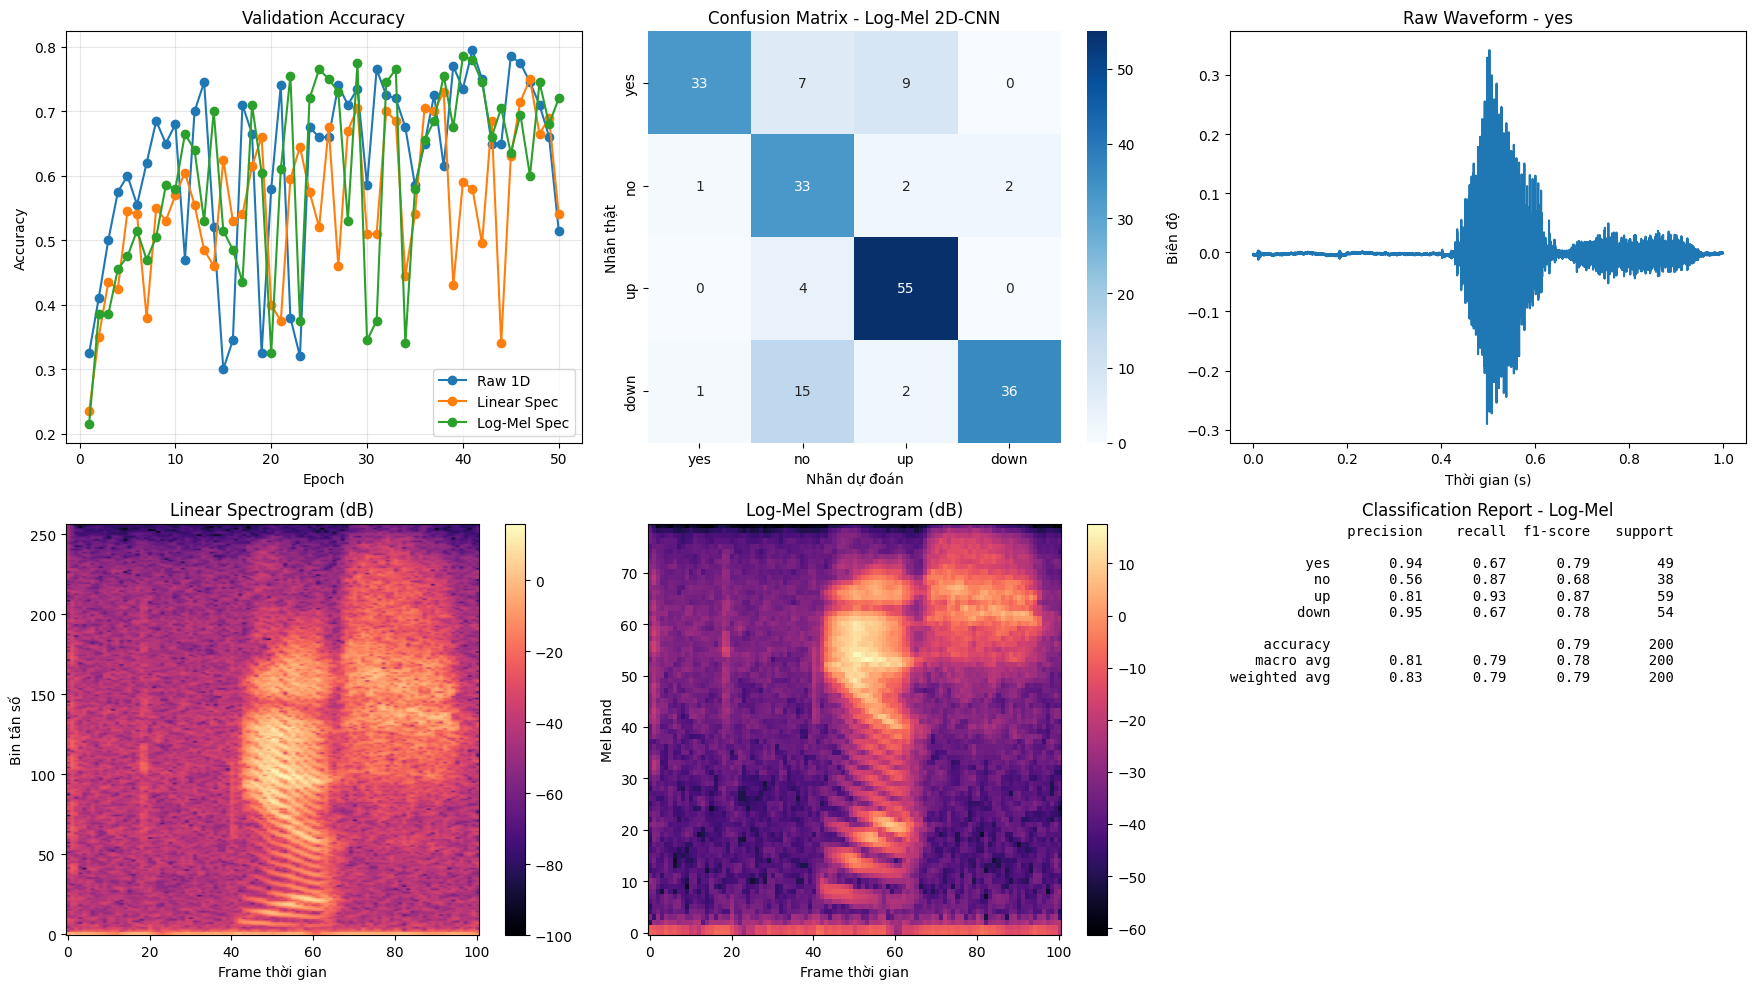

In [7]:
# TODO 6: Vẽ Learning Curves, Confusion Matrix và các dạng biểu diễn
epoch_numbers = range(1, epochs + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].plot(epoch_numbers, raw_accs, marker='o', label='Raw 1D')
axes[0, 0].plot(epoch_numbers, linear_accs, marker='o', label='Linear Spec')
axes[0, 0].plot(epoch_numbers, logmel_accs, marker='o', label='Log-Mel Spec')
axes[0, 0].set_title('Validation Accuracy')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Accuracy')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

cm = confusion_matrix(logmel_true, logmel_pred, labels=range(len(CLASSES)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0, 1])
axes[0, 1].set_title('Confusion Matrix - Log-Mel 2D-CNN')
axes[0, 1].set_xlabel('Nhãn dự đoán')
axes[0, 1].set_ylabel('Nhãn thật')

sample_wave, sample_label = full_dataset[0]
time_axis = np.arange(sample_wave.shape[1]) / 16000
axes[0, 2].plot(time_axis, sample_wave.squeeze().numpy())
axes[0, 2].set_title(f'Raw Waveform - {CLASSES[sample_label]}')
axes[0, 2].set_xlabel('Thời gian (s)')
axes[0, 2].set_ylabel('Biên độ')

linear_spec = transform_linear(sample_wave.to(device)).squeeze().detach().cpu().numpy()
img1 = axes[1, 0].imshow(linear_spec, origin='lower', aspect='auto', cmap='magma')
axes[1, 0].set_title('Linear Spectrogram (dB)')
axes[1, 0].set_xlabel('Frame thời gian')
axes[1, 0].set_ylabel('Bin tần số')
fig.colorbar(img1, ax=axes[1, 0])

logmel_spec = transform_logmel(sample_wave.to(device)).squeeze().detach().cpu().numpy()
img2 = axes[1, 1].imshow(logmel_spec, origin='lower', aspect='auto', cmap='magma')
axes[1, 1].set_title('Log-Mel Spectrogram (dB)')
axes[1, 1].set_xlabel('Frame thời gian')
axes[1, 1].set_ylabel('Mel band')
fig.colorbar(img2, ax=axes[1, 1])

axes[1, 2].axis('off')
axes[1, 2].text(
    0.0,
    1.0,
    classification_report(
        logmel_true,
        logmel_pred,
        labels=range(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    ),
    family='monospace',
    va='top'
)
axes[1, 2].set_title('Classification Report - Log-Mel')

plt.tight_layout()
plt.show()

## 8. Câu hỏi thảo luận & Mở rộng

**Câu hỏi 1:** Tại sao Log-Mel Spectrogram thường phù hợp hơn Linear Spectrogram và Raw Waveform cho CNN phân loại âm thanh?

**Trả lời:** Tai người cảm nhận tần số gần theo thang Mel: phân biệt rất kỹ ở vùng tần số thấp và thô hơn ở vùng cao. Mel filter bank nén các bin tần số tuyến tính theo cách gần với cơ chế nghe này, vừa giảm kích thước đầu vào vừa giữ các dải quan trọng của tiếng nói. Phổ hai chiều còn làm rõ mẫu cục bộ theo thời gian và tần số, nên Conv2D dễ phát hiện formant, phụ âm và sự chuyển tiếp âm tiết. Khi cao độ hoặc cách phát âm dịch nhẹ, mẫu phổ chỉ dịch chuyển cục bộ; phép tích chập và pooling giúp mô hình ít nhạy với dịch chuyển đó hơn. Raw waveform chưa biểu diễn tần số trực tiếp, còn Linear Spectrogram dành nhiều bin cho vùng tần số cao không phải lúc nào cũng hữu ích cho tiếng nói.

**Câu hỏi 2:** AmplitudeToDB có vai trò gì? Điều gì xảy ra nếu đưa năng lượng Mel tuyến tính trực tiếp vào CNN?

**Trả lời:** Năng lượng âm thanh có dải động rất lớn: một số ô phổ có thể mạnh hơn các ô khác hàng nghìn lần. Phép logarithm chuyển tỉ lệ nhân thành chênh lệch cộng và nén các giá trị cực lớn, nhờ đó cả thành phần mạnh lẫn yếu đều hiện rõ hơn. Nếu dùng trực tiếp năng lượng tuyến tính, vài ô năng lượng lớn có thể chi phối loss và gradient, còn nhiều cấu trúc yếu nhận gradient rất nhỏ. Quá trình học vì thế dễ dao động, hội tụ chậm và nhạy với âm lượng. Batch normalization có hỗ trợ nhưng không thay thế hoàn toàn ý nghĩa nén dải động của thang dB.